In [1]:
# ============================
# Imports & configuration
# ============================
import os
import numpy as np
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pathlib import Path
from math import gcd
from scipy.signal import butter, filtfilt, hilbert, resample_poly
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from scipy.interpolate import interp1d

# ---- session setup (edit here) ----
DATA_ROOT_HINT = "data/crcns_mouse"  # relative hint; auto-resolved below
SESSION = "ec013.156"          # e.g. ec013.156, ec013.157, ec013.248, ec013.250
CORRECTED_SECTION = "auto"      # e.g. "ec013.21" for corrected section; "auto" to detect
PREFER_CORRECTED_SECTION = True  # prefer nested corrected section when both exist
TRACK_MODE = "auto"             # "auto", "linear", "2d"

# ---- constants ----
THETA_BAND = (4, 12)      # Hz
FS_OUTS = [1250, 100, 50] # downsampled LFP outputs to compare
CROP_SEC = (0, 110)       # snippet for overlay


def resolve_data_root(data_root_hint: str) -> Path:
    """Resolve crcns_mouse root robustly across notebook working dirs."""
    cwd = Path.cwd()
    candidates = [
        Path(data_root_hint),
        cwd / data_root_hint,
        cwd.parent / "data" / "crcns_mouse",
        cwd.parent.parent / "data" / "crcns_mouse",
        Path("d:/comets/data/crcns_mouse"),
        Path("d:/wristband/data/crcns_mouse"),
    ]

    seen = set()
    for c in candidates:
        c = c.resolve()
        key = str(c).lower()
        if key in seen:
            continue
        seen.add(key)
        if c.exists():
            return c

    tried = "\n".join(str(p.resolve()) for p in candidates)
    raise FileNotFoundError(
        "Could not locate crcns_mouse data root. Tried:\n" + tried
    )


def resolve_session_dir(data_root: Path, session: str, corrected_section: str = "auto", prefer_corrected: bool = True) -> Path:
    session_root = data_root / session
    direct = session_root if (session_root / f"{session}.eeg").exists() else None

    nested = []
    if session_root.exists():
        nested = sorted([
            p for p in session_root.glob(f"*/{session}")
            if (p / f"{session}.eeg").exists()
        ])

    if corrected_section != "auto":
        forced = session_root / corrected_section / session
        if (forced / f"{session}.eeg").exists():
            return forced
        raise FileNotFoundError(f"Corrected section not found: {forced}")

    if prefer_corrected and nested:
        return nested[0]
    if direct is not None:
        return direct
    if nested:
        return nested[0]

    raise FileNotFoundError(
        f"Could not find session files for {session} under {session_root}"
    )


def infer_track_mode(session: str, track_mode: str = "auto") -> str:
    if track_mode in {"linear", "2d"}:
        return track_mode

    linear_sessions = {"ec013.156", "ec013.157"}
    arena_sessions = {"ec013.248", "ec013.250"}

    if session in linear_sessions:
        return "linear"
    if session in arena_sessions:
        return "2d"

    return "2d"


DATA_ROOT = resolve_data_root(DATA_ROOT_HINT)
session = SESSION
track_mode = infer_track_mode(session, TRACK_MODE)
session_dir = resolve_session_dir(DATA_ROOT, session, CORRECTED_SECTION, PREFER_CORRECTED_SECTION)

eeg_path = str(session_dir / f"{session}.eeg")
xml_path = str(session_dir / f"{session}.xml")
whl_path = str(session_dir / f"{session}.whl")
spk_dir = str(session_dir)

print(f"DATA_ROOT: {DATA_ROOT}")
print(f"session: {session}")
print(f"track_mode: {track_mode}")
print(f"session_dir: {session_dir}")
print(f"eeg_path: {eeg_path}")
print(f"xml_path: {xml_path}")
print(f"whl_path: {whl_path}")


DATA_ROOT: /mnt/d/comets/data/crcns_mouse
session: ec013.156
track_mode: linear
session_dir: /mnt/d/comets/data/crcns_mouse/ec013.156
eeg_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.eeg
xml_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.xml
whl_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.whl


In [2]:


def resolve_session_dir(data_root: Path, session: str, corrected_section: str = "auto", prefer_corrected: bool = True) -> Path:
    session_root = data_root / session
    direct = session_root if (session_root / f"{session}.eeg").exists() else None

    nested = []
    if session_root.exists():
        nested = sorted([
            p for p in session_root.glob(f"*/{session}")
            if (p / f"{session}.eeg").exists()
        ])

    if corrected_section != "auto":
        forced = session_root / corrected_section / session
        if (forced / f"{session}.eeg").exists():
            return forced
        raise FileNotFoundError(f"Corrected section not found: {forced}")

    if prefer_corrected and nested:
        return nested[0]
    if direct is not None:
        return direct
    if nested:
        return nested[0]

    raise FileNotFoundError(
        f"Could not find session files for {session} under {session_root}"
    )


def infer_track_mode(session: str, track_mode: str = "auto") -> str:
    if track_mode in {"linear", "2d"}:
        return track_mode

    linear_sessions = {"ec013.156", "ec013.157"}
    arena_sessions = {"ec013.248", "ec013.250"}

    if session in linear_sessions:
        return "linear"
    if session in arena_sessions:
        return "2d"

    return "2d"


session = SESSION
track_mode = infer_track_mode(session, TRACK_MODE)
session_dir = resolve_session_dir(DATA_ROOT, session, CORRECTED_SECTION, PREFER_CORRECTED_SECTION)

eeg_path = str(session_dir / f"{session}.eeg")
xml_path = str(session_dir / f"{session}.xml")
whl_path = str(session_dir / f"{session}.whl")
spk_dir = str(session_dir)

print(f"session: {session}")
print(f"track_mode: {track_mode}")
print(f"session_dir: {session_dir}")
print(f"eeg_path: {eeg_path}")
print(f"xml_path: {xml_path}")
print(f"whl_path: {whl_path}")


session: ec013.156
track_mode: linear
session_dir: /mnt/d/comets/data/crcns_mouse/ec013.156
eeg_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.eeg
xml_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.xml
whl_path: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156.whl


In [3]:
import sys
from pathlib import Path

# Resolve repo root by locating code/utilities/get_neuraldata_hsntools.py
repo_root = next(
    (q for q in [Path.cwd(), *Path.cwd().parents]
     if (q / "code" / "utilities" / "get_neuraldata_hsntools.py").exists()),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "Could not find code/utilities/get_neuraldata_hsntools.py from current directory."
    )

# Add the repo's code directory so 'utilities' can be imported.
code_dir = repo_root / "code"
if str(code_dir) not in sys.path:
    sys.path.insert(0, str(code_dir))

from utilities.get_neuraldata_hsntools import get_spike_indx


In [4]:
# ============================
# Load LFP + metadata
# ============================
tree = ET.parse(xml_path); root = tree.getroot()
n_channels = int(root.find("acquisitionSystem/nChannels").text)
fs_lfp     = int(root.find("fieldPotentials/lfpSamplingRate").text)

raw = np.fromfile(eeg_path, dtype=np.int16)
n_samples = raw.size // n_channels
lfp = raw.reshape((n_samples, n_channels)).T.astype(np.float32)  # (n_ch, n_samp)

duration_sec = lfp.shape[1] / fs_lfp
print(f"LFP: {lfp.shape}, fs={fs_lfp} Hz, durÃ¢â€°Ë†{duration_sec:.1f}s")


LFP: (65, 1279488), fs=1250 Hz, durÃ¢â€°Ë†1023.6s


In [5]:
# ============================
# Theta envelope & downsampling
# ============================
def bandpass(x, lo, hi, fs, order=4, axis=-1):
    nyq = 0.5*fs
    b, a = butter(order, [lo/nyq, hi/nyq], btype="band")
    return filtfilt(b, a, x, axis=axis)

# 1) filter to theta
lfp_theta = bandpass(lfp, THETA_BAND[0], THETA_BAND[1], fs_lfp, axis=1)

# 2) Hilbert envelope per channel
env = np.abs(hilbert(lfp_theta, axis=1))  # (n_ch, n_samp)

# 3) (optional) light smooth pre-downsample, helps anti-alias
env_sm = gaussian_filter1d(env, sigma=int(0.04*fs_lfp), axis=1, mode="nearest")  # ~40 ms
env_ds = {}
for fs_out in FS_OUTS:
    # polyphase resample to fs_out
    # use integers for stability
    
    up = fs_out
    down = fs_lfp
    g = gcd(up, down)
    up //= g; down //= g
    env_tgt = resample_poly(env_sm, up, down, axis=1)
    env_ds[fs_out] = env_tgt  # (n_ch, T_out)
    print(f"theta envelope @ {fs_out} Hz:", env_tgt.shape)


theta envelope @ 1250 Hz: (65, 1279488)
theta envelope @ 100 Hz: (65, 102360)
theta envelope @ 50 Hz: (65, 51180)


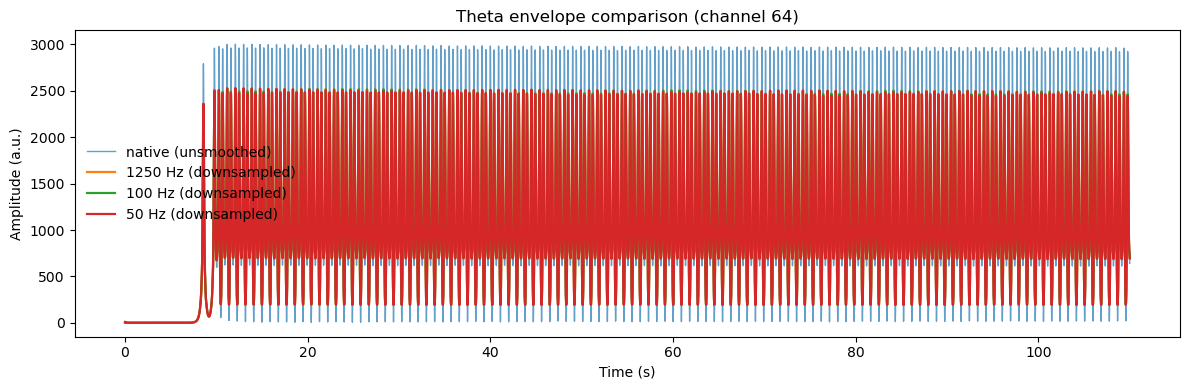

In [6]:
# ============================
# Compare 100 Hz vs 50 Hz envelopes
# Native trace = UNSMOOTHED
# ============================
ch = 64  # pick an LFP channel to visualize
t0, t1 = CROP_SEC
idx_native = slice(int(t0*fs_lfp), int(t1*fs_lfp))

# --- native (UNSMOOTHED) envelope for reference ---
t_native = np.arange(idx_native.stop - idx_native.start) / fs_lfp + t0
y_native = env[ch, idx_native]  # <-- use UNSMOOTHED envelope here

plt.figure(figsize=(12, 4))
plt.plot(t_native, y_native, lw=1.0, alpha=0.7, label="native (unsmoothed)")

# --- downsampled curves (these were built from env_sm for anti-alias) ---
for fs_out, arr in env_ds.items():
    T = arr.shape[1]
    t_out = np.arange(T) / fs_out
    mask = (t_out >= t0) & (t_out <= t1)
    plt.plot(t_out[mask], arr[ch, mask], lw=1.6, label=f"{fs_out} Hz (downsampled)")

plt.title(f"Theta envelope comparison (channel {ch})")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


In [7]:
# ============================
# Load spikes (per your helper)
# ============================
fs_spike = 20000
spike_dict, n_units = get_spike_indx(spk_dir)
print(f"Units: {n_units} across {len(spike_dict)} electrodes")

# collect spike times (seconds) per unit
spike_times = []
for _, units in spike_dict.items():
    for _, st in units.items():
        spike_times.append(st / fs_spike)  # seconds
n_units = len(spike_times)
print("Collected units:", n_units)


Elec 0: 21 Clusters
Elec 1: 20 Clusters
Elec 2: 18 Clusters
Elec 3: 16 Clusters
Elec 4: 7 Clusters
Elec 5: 7 Clusters
Elec 6: 7 Clusters
Elec 7: 3 Clusters
Units: 99 across 8 electrodes
Collected units: 83


In [8]:
# ============================
# Spike builders
# ============================
def spike_counts(spike_times_list, bin_edges_s):
    """Return (T, n_units) counts per bin."""
    mats = [np.histogram(st, bins=bin_edges_s)[0] for st in spike_times_list]
    return np.stack(mats, axis=1).astype(np.float32)


def moving_avg_counts_100Hz(spike_times_list, win_ms=100, hop_ms=10, dur_s=None):
    """
    Moving window counts @ 100 Hz (10 ms hop).
    Centered window -> zero-phase look; switch to causal if you need causality.
    """
    fs_out = int(1000 / hop_ms)
    T = int(np.floor((dur_s) * fs_out)) if dur_s is not None else None

    # 1) 10 ms non-overlap counts
    base_edges = np.arange(0, dur_s + 1e-9, 0.01)  # 10 ms
    C10 = spike_counts(spike_times_list, base_edges)  # (T10, n_units)

    # 2) convolve with 100 ms boxcar in samples (100/10 = 10 taps)
    k = int(win_ms / hop_ms)  # 10 taps
    box = np.ones(k, dtype=np.float32)
    C100MA = np.apply_along_axis(lambda x: np.convolve(x, box, mode="same"), 0, C10)

    # 3) convert to Hz: sum over 100 ms / 0.1 s
    rate = (C100MA / 0.1).astype(np.float32)
    return rate, fs_out


def nonoverlap_counts(spike_times_list, bin_ms, dur_s):
    """Non-overlap counts per bin_ms, returned as counts/bin on that grid."""
    dt = bin_ms / 1000
    edges = np.arange(0, dur_s + 1e-9, dt)
    C = spike_counts(spike_times_list, edges)  # counts/bin
    fs_out = int(round(1 / dt))
    return C, fs_out, dt


def counts_to_rate(C, dt):
    """Convert counts/bin to Hz."""
    return (C / dt).astype(np.float32)


dur_s = duration_sec  # align to LFP duration

# Non-overlap binned counts for direct comparison
C20, fs_20, dt_20 = nonoverlap_counts(spike_times, 20, dur_s)      # 50 Hz
C50, fs_50, dt_50 = nonoverlap_counts(spike_times, 50, dur_s)      # 20 Hz
C100, fs_100, dt_100 = nonoverlap_counts(spike_times, 100, dur_s)  # 10 Hz

# Convert counts/bin to firing rate (Hz)
S20 = counts_to_rate(C20, dt_20)
S50 = counts_to_rate(C50, dt_50)
S100 = counts_to_rate(C100, dt_100)

# Sampling rates (equivalent to fs = 1000 / bin_ms)
fs_S20 = fs_20
fs_S50 = fs_50
fs_S100 = fs_100

# Backward-compatible aliases used later in this notebook
C3, fs_C3, dt_C3 = C20, fs_20, dt_20
S3, fs_S3 = S20, fs_S20

print("Counts:", "20ms", C20.shape, "50ms", C50.shape, "100ms", C100.shape)
print("Rates:", "20ms", S20.shape, f"@{fs_S20}Hz", "50ms", S50.shape, f"@{fs_S50}Hz", "100ms", S100.shape, f"@{fs_S100}Hz")


Counts: 20ms (51179, 83) 50ms (20471, 83) 100ms (10235, 83)
Rates: 20ms (51179, 83) @50Hz 50ms (20471, 83) @20Hz 100ms (10235, 83) @10Hz


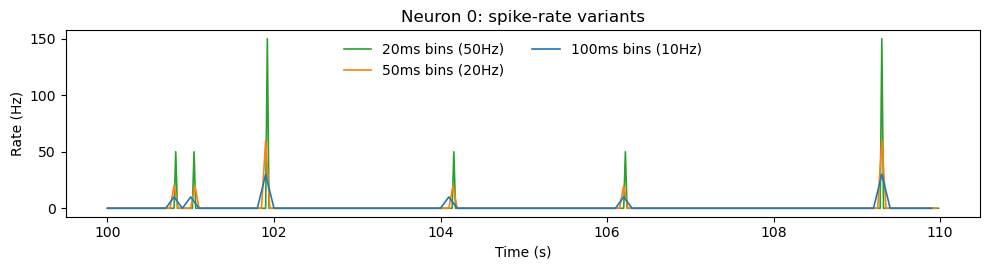

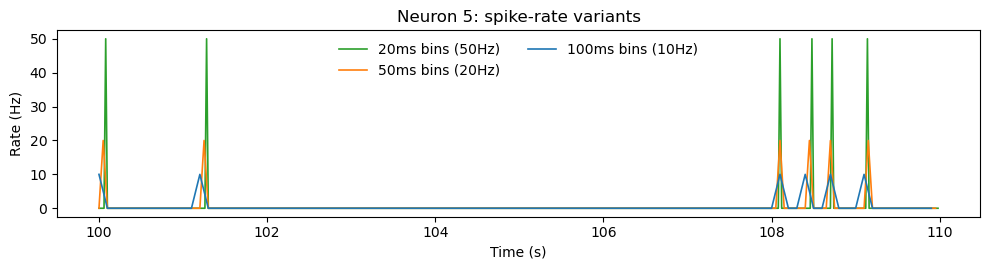

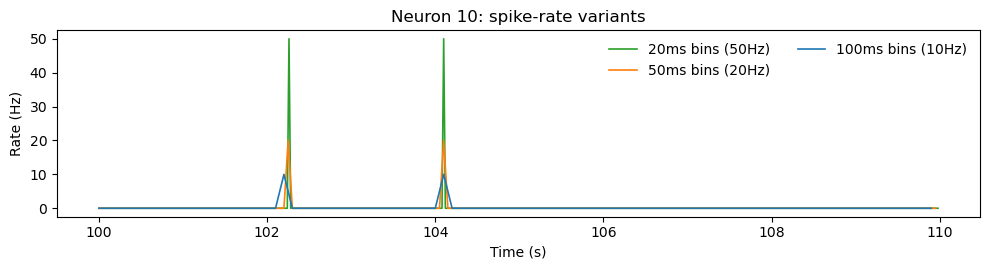

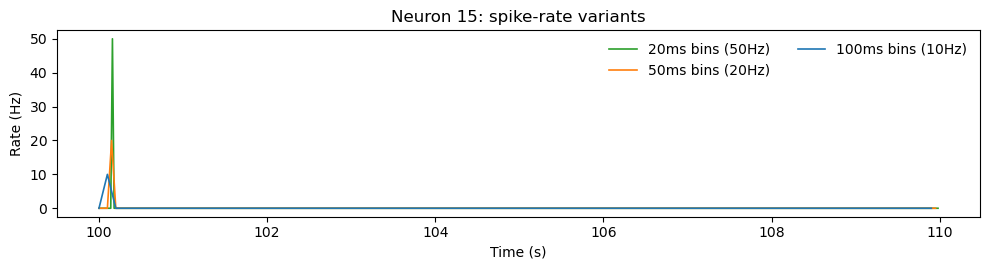

In [9]:
# ============================
# Quick comparison plots
# ============================
neurons_to_show = [0, 5, 10, 15][:min(4, n_units)]
twin = 10.0   # seconds to visualize
t0 = 100.0   # start time

def plot_variant(ax, rate, fs, label, color):
    i0 = int(t0*fs); i1 = int((t0+twin)*fs)
    t = np.arange(i1-i0)/fs + t0
    ax.plot(t, rate[i0:i1], lw=1.2, label=label, color=color, )
for nu in neurons_to_show:
    fig, ax = plt.subplots(figsize=(10,2.8))
    plot_variant(ax, S20[:,nu], fs_S20, "20ms bins (50Hz)", "C2")
    plot_variant(ax, S50[:,nu], fs_S50, "50ms bins (20Hz)", "C1")
    plot_variant(ax, S100[:,nu], fs_S100, "100ms bins (10Hz)", "C0")
    ax.set_ylabel("Rate (Hz)"); ax.set_xlabel("Time (s)")
    ax.set_title(f"Neuron {nu}: spike-rate variants")
    ax.legend(frameon=False, ncols=2); plt.tight_layout(); plt.show()


In [10]:
fs_target = 50
up = fs_target
down = fs_lfp
g = gcd(up, down)
up //= g; down //= g

lfp_theta_50hz = resample_poly(lfp_theta, up, down, axis=1)
print("lfp_theta_50hz:", lfp_theta_50hz.shape)
print("lfp_raw:", lfp.shape)

lfp_theta_50hz: (65, 51180)
lfp_raw: (65, 1279488)


In [11]:
# ============================================================
# 2) Prepare final spike outputs
# ============================================================

# Raw spike event structure
spike_raw = spike_dict

# Canonical 20 ms bin representation: counts/bin (NOT Hz)
spike_bin = C3.copy()               # counts per 20 ms bin
spike_bin_dt = dt_C3                # 0.02 s

# Derived 20 ms firing rate (Hz)
spike_rate_20ms = counts_to_rate(spike_bin, spike_bin_dt)

# Smoothed firing rate in Hz (zero-phase Gaussian)
# sigma ~= 40 ms -> 2 bins at 50 Hz
sigma_bins = 2
spike_rate_smooth_no_latency = gaussian_filter1d(
    spike_rate_20ms,
    sigma=sigma_bins,
    axis=0,
    mode="nearest"
)

print("spike_bin (counts):", spike_bin.shape, "dt:", spike_bin_dt)
print("spike_rate_20ms (Hz):", spike_rate_20ms.shape)
print("spike_rate_smooth_no_latency (Hz):", spike_rate_smooth_no_latency.shape)


spike_bin (counts): (51179, 83) dt: 0.02
spike_rate_20ms (Hz): (51179, 83)
spike_rate_smooth_no_latency (Hz): (51179, 83)


In [12]:
# ============================================================
# Load and clean position from .whl
# ============================================================

# --- load raw .whl file ---
whl_data = np.loadtxt(whl_path)   # shape: (n_samples, 4) = LED1(x,y), LED2(x,y)
print("Raw .whl shape:", whl_data.shape)

# Copy the data for processing
whl_cleaned = whl_data.copy()

# Fill missing values (-1) with forward/backward fill per column
for i in range(whl_cleaned.shape[1]):
    col = whl_cleaned[:, i]
    col[col == -1] = np.nan

    # Forward fill
    mask = np.isnan(col)
    idx = np.where(~mask, np.arange(mask.size), 0)
    np.maximum.accumulate(idx, out=idx)
    col = col[idx]

    # Backward fill
    mask = np.isnan(col)
    idx = np.where(~mask, np.arange(mask.size), mask.size - 1)
    np.minimum.accumulate(idx[::-1], out=idx[::-1])
    col = col[idx]

    whl_cleaned[:, i] = col

# Extract LED positions and midpoint trajectory in native camera time
x1, y1, x2, y2 = whl_cleaned.T
pos2d_raw = np.column_stack(((x1 + x2) / 2, (y1 + y2) / 2))

# Define the native-rate position target before any resampling
if track_mode == "linear":
    pca = PCA(n_components=1)
    position_raw = pca.fit_transform(pos2d_raw).reshape(-1)
else:
    pca = None
    position_raw = pos2d_raw

print(f"position_raw (mode={track_mode}): {position_raw.shape}")



Raw .whl shape: (39985, 4)
position_raw (mode=linear): (39985,)


Position aligned:
position_raw: (39985,), position_50hz: (51180,)
speed_50hz: (51180,), head_dir_50hz: (51180,)
Common sampling rate: 50 Hz, duration: 1023.6 s


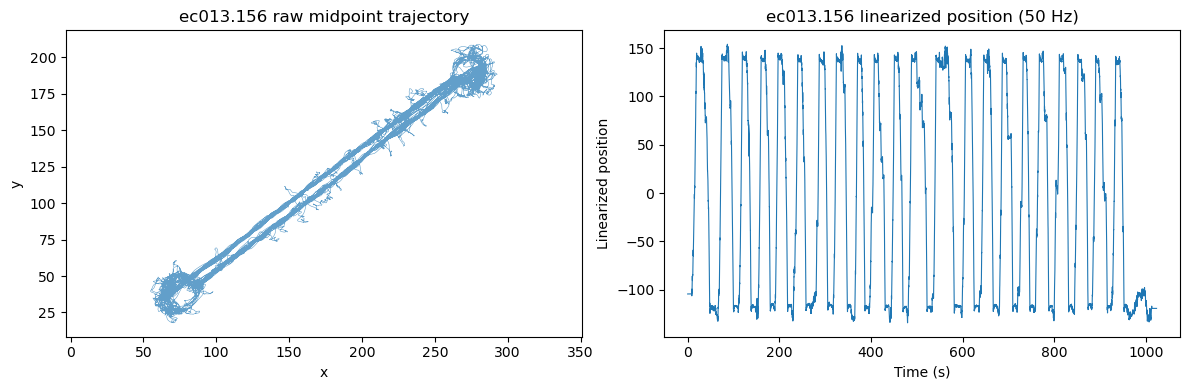

In [13]:
# ============================================================
# Align position to fs_target and build native/50 Hz targets
# ============================================================

duration_sec = lfp.shape[1] / fs_lfp
fs_pos = whl_cleaned.shape[0] / duration_sec

t_camera = np.arange(len(pos2d_raw)) / fs_pos
t_target = np.arange(0, duration_sec, 1 / fs_target)

# Interpolate LED traces to target rate for 2D diagnostics and features
fx1 = interp1d(t_camera, x1, kind="linear", fill_value="extrapolate")
fy1 = interp1d(t_camera, y1, kind="linear", fill_value="extrapolate")
fx2 = interp1d(t_camera, x2, kind="linear", fill_value="extrapolate")
fy2 = interp1d(t_camera, y2, kind="linear", fill_value="extrapolate")

x1_50hz = fx1(t_target)
y1_50hz = fy1(t_target)
x2_50hz = fx2(t_target)
y2_50hz = fy2(t_target)
pos2d_50hz = np.column_stack(((x1_50hz + x2_50hz) / 2, (y1_50hz + y2_50hz) / 2))

# Resample the canonical target stream after it has been defined in native time
if track_mode == "linear":
    fpos = interp1d(t_camera, position_raw, kind="linear", fill_value="extrapolate")
    position_50hz = fpos(t_target).reshape(-1)
else:
    fx = interp1d(t_camera, position_raw[:, 0], kind="linear", fill_value="extrapolate")
    fy = interp1d(t_camera, position_raw[:, 1], kind="linear", fill_value="extrapolate")
    position_50hz = np.column_stack((fx(t_target), fy(t_target)))

# Optional behavior features (mainly useful for 2D sessions)
vel_xy_50hz = np.gradient(pos2d_50hz, axis=0) * fs_target
speed_50hz = np.linalg.norm(vel_xy_50hz, axis=1)
head_dir_50hz = np.arctan2(y2_50hz - y1_50hz, x2_50hz - x1_50hz)

print("Position aligned:")
print(f"position_raw: {position_raw.shape}, position_50hz: {position_50hz.shape}")
print(f"speed_50hz: {speed_50hz.shape}, head_dir_50hz: {head_dir_50hz.shape}")
print(f"Common sampling rate: {fs_target} Hz, duration: {len(t_target)/fs_target:.1f} s")

# --- mode-specific visualization ---
if track_mode == "linear":
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    axs[0].plot(pos2d_raw[:, 0], pos2d_raw[:, 1], lw=0.4, alpha=0.7)
    axs[0].set_title(f"{session} raw midpoint trajectory")
    axs[0].set_xlabel("x")
    axs[0].set_ylabel("y")
    axs[0].axis("equal")

    axs[1].plot(t_target, position_50hz, lw=0.8)
    axs[1].set_title(f"{session} linearized position (50 Hz)")
    axs[1].set_xlabel("Time (s)")
    axs[1].set_ylabel("Linearized position")

    plt.tight_layout()
    plt.show()

else:
    # 2D square-arena diagnostics
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.scatter(np.where(whl_data[:, 0] == -1)[0], np.full((whl_data[:, 0] == -1).sum(), -5), s=1, alpha=0.5, label="LED1 missing")
    ax.scatter(np.where(whl_data[:, 2] == -1)[0], np.full((whl_data[:, 2] == -1).sum(), -10), s=1, alpha=0.5, label="LED2 missing")
    ax.set_title("Missing LED samples in raw .whl")
    ax.set_xlabel("Frame index")
    ax.set_yticks([])
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 6))
    plt.plot(position_50hz[:, 0], position_50hz[:, 1], lw=0.4, alpha=0.7)
    plt.scatter(position_50hz[0, 0], position_50hz[0, 1], s=20, label="start")
    plt.scatter(position_50hz[-1, 0], position_50hz[-1, 1], s=20, label="end")
    plt.title(f"{session} trajectory (2D)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 6))
    plt.hist2d(position_50hz[:, 0], position_50hz[:, 1], bins=60)
    plt.title(f"{session} occupancy map (2D)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")
    plt.colorbar(label="samples")
    plt.tight_layout()
    plt.show()

    win_start, win_end = 30.0, 80.0
    mask = (t_target >= win_start) & (t_target <= win_end)

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    np.random.seed(42)
    selected_channels = np.random.choice(lfp.shape[0], size=min(5, lfp.shape[0]), replace=False)
    for ch in selected_channels:
        axs[0, 0].plot(np.arange(lfp.shape[1]) / fs_lfp, lfp[ch], lw=0.2)
    axs[0, 0].set_xlim(win_start, win_end)
    axs[0, 0].set_title(f"Raw LFP ({len(selected_channels)} random channels)")
    axs[0, 0].set_xlabel("Time (s)")
    axs[0, 0].set_ylabel("Amplitude")

    axs[0, 1].plot(t_target[mask], position_50hz[mask, 0], lw=1.0, label="x")
    axs[0, 1].plot(t_target[mask], position_50hz[mask, 1], lw=1.0, label="y")
    axs[0, 1].set_title("Position components (window)")
    axs[0, 1].set_xlabel("Time (s)")
    axs[0, 1].set_ylabel("Position")
    axs[0, 1].legend(frameon=False)

    ax_polar = plt.subplot(2, 2, 3, polar=True)
    time_norm = (t_target[mask] - t_target[mask].min()) / (t_target[mask].ptp() + 1e-9)
    sc = ax_polar.scatter(head_dir_50hz[mask], np.ones(mask.sum()), c=time_norm, cmap="plasma", s=1, alpha=0.6)
    ax_polar.set_title("Head direction (polar, colored by time)")
    plt.colorbar(sc, ax=ax_polar, pad=0.1, label="time (norm)")

    axs[1, 1].plot(t_target[mask], speed_50hz[mask], color="green", lw=1.0)
    axs[1, 1].set_title("Speed (window)")
    axs[1, 1].set_xlabel("Time (s)")
    axs[1, 1].set_ylabel("speed (units/s)")

    plt.tight_layout(pad=2.0)
    plt.show()

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, polar=True)
    counts, bin_edges = np.histogram(head_dir_50hz, bins=36, range=(-np.pi, np.pi))
    widths = np.diff(bin_edges)
    angles = bin_edges[:-1] + widths / 2
    ax.bar(angles, counts, width=widths, bottom=0.0, color="orange", alpha=0.7, edgecolor="k")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title("Circular histogram of head direction")
    plt.tight_layout()
    plt.show()



In [14]:
# ============================================================
# Trim all streams to a shared length
# ============================================================

T = min(
    lfp_theta_50hz.shape[1],
    spike_bin.shape[0],
    spike_rate_20ms.shape[0],
    spike_rate_smooth_no_latency.shape[0],
    position_50hz.shape[0],
)

lfp_theta_50hz = lfp_theta_50hz[:, :T]
spike_bin = spike_bin[:T, :]
spike_rate_20ms = spike_rate_20ms[:T, :]
spike_rate_smooth_no_latency = spike_rate_smooth_no_latency[:T, :]
position_50hz = position_50hz[:T]
vel_xy_50hz = vel_xy_50hz[:T, :]
speed_50hz = speed_50hz[:T]
head_dir_50hz = head_dir_50hz[:T]

print(f"Final aligned length T: {T}")
print(f"position_50hz (mode={track_mode}): {position_50hz.shape}")



Final aligned length T: 51179
position_50hz (mode=linear): (51179,)


In [15]:
lfp_theta.shape

(65, 1279488)

In [16]:
# ============================================================
# Package and save
# ============================================================

import pickle

dataset = {
    "session": session,
    "session_dir": str(session_dir),
    "track_mode": track_mode,
    "lfp_raw": lfp.T,                                 # [n_ch, n_samples_native]
    "lfp_theta": lfp_theta_50hz.T,                    # [n_ch, n_samples_50hz]
    "spike_raw": spike_raw,                           # dict, per electrode/unit raw spike times
    "spike_bin": spike_bin,                           # [n_bins_50hz, n_units], counts per 20 ms bin
    "spike_rate": spike_rate_20ms,                    # [n_bins_50hz, n_units], Hz (derived from spike_bin)
    "spike_bin_smoothed": spike_rate_smooth_no_latency,  # [n_bins_50hz, n_units], smoothed Hz
    "fs_lfp": fs_lfp,
    "fs_common": fs_target,
    "theta_band": THETA_BAND,
    "bin_size_ms_spike": 20,
    "position_raw": position_raw,
    "position_50hz": position_50hz,
    "speed": speed_50hz,
    "head_direction": head_dir_50hz,
}

SAVE_PKL = False
save_path = session_dir / f"{session}_lfp_spike.pkl"

if SAVE_PKL:
    with open(save_path, "wb") as f:
        pickle.dump(dataset, f)
    print(f"Saved: {save_path}")
else:
    print("SAVE_PKL=False, dataset prepared but not written")
    print("dataset keys:", sorted(dataset.keys()))



SAVE_PKL=False, dataset prepared but not written
dataset keys: ['bin_size_ms_spike', 'fs_common', 'fs_lfp', 'head_direction', 'lfp_raw', 'lfp_theta', 'position_50hz', 'position_raw', 'session', 'session_dir', 'speed', 'spike_bin', 'spike_bin_smoothed', 'spike_rate', 'spike_raw', 'theta_band', 'track_mode']


In [17]:
position_50hz.shape, position_raw.shape

((51179,), (39985,))